# 05. 성능 개선 실험 — 그룹 동시 학습 · soft label · seed 앙상블

**목표**: 서비스 기준(행성 감정 그룹 10개 + ‘없음’) 성능을 0.75 이상으로 올릴 수 있는지 확인한다.

| 단계 | 실험 | 모델 |
|---|---|---|
| 1 | 2×2 실험: 그룹 동시 학습(44+11 다중 과제) × soft label(평가자 투표 비율) | KcELECTRA-base, seed 42 |
| 2 | 1단계 최고 방식을 큰 모델에 적용 | KLUE-RoBERTa-large, seed 42 |
| 3 | seed 43, 44 반복 → seed 앙상블, 모델 간 앙상블 | KcELECTRA(1단계 선택 방식), KLUE-large(이진 라벨, 2단계 결과로 변경) |

**미리 정한 규칙** (결과를 보기 전에 정함)
- 학습 방식 선택: validation 그룹 macro-F1이 가장 높은 방식(그룹 점수는 그룹 출력과 라벨 유도 중 validation에서 높은 쪽)
- 앙상블 선택: 아래 후보 중 validation 그룹 macro-F1이 가장 높은 것
- 모든 threshold는 validation에서 정하고 test에는 그대로 적용한다. 평가는 항상 공식 이진 라벨(그룹은 그 OR)로 한다.

**계획 변경 (2단계 결과 반영)**: 1단계에서 고른 방식(다중 과제 + soft label)은 KLUE-large에서 기존 이진 라벨 방식보다 validation 성능이 낮았다(그룹 0.714 vs 0.717, 라벨 0.566 vs 0.582).
그래서 3단계의 KLUE-large seed 반복은 validation 성능이 더 높은 **이진 라벨 방식**으로 바꿨다. 앙상블 후보는 seed 결과를 보기 전에 다시 정했다(4.2절).

학습: `ai/scripts/train_emotion.py` · 설정: `ai/configs/exp_*.json`, `emotion_klue_roberta_large.json`

## 1. 환경과 결과 불러오기

In [1]:
import os
import sys
import json
import platform
from pathlib import Path


def find_ai_root(start: Path) -> Path:
    """현재 위치에서 위로 올라가며 ai/ 폴더를 찾는다(저장소 루트·ai/·ai/notebooks/ 모두 지원)."""
    for p in [start, *start.parents]:
        if p.name == "ai" and (p / "src" / "data" / "paths.py").is_file():
            return p
        if (p / "ai" / "src" / "data" / "paths.py").is_file():
            return p / "ai"
    raise FileNotFoundError("ai/ 폴더를 찾지 못했습니다. 저장소 안에서 실행하세요.")


AI_ROOT = find_ai_root(Path.cwd().resolve())
if str(AI_ROOT) not in sys.path:
    sys.path.insert(0, str(AI_ROOT))

# 커널 점검: 저장소 .venv(학습 패키지 포함)가 아니면 여기서 멈추고 안내한다.
from src.env_check import assert_environment
ENV = assert_environment(AI_ROOT / "requirements-train.txt", AI_ROOT.parent)

from src.data.paths import get_paths, configure_hf_cache, load_json

P = get_paths(AI_ROOT)
configure_hf_cache(P)                       # transformers import 전에 호출
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"


def rel(p) -> str:
    return Path(p).resolve().relative_to(P.repo_root).as_posix()

Python 3.13.5 | 저장소 .venv 커널 사용: 예
  numpy            필요 2.5.3      설치 2.5.3            OK
  pandas           필요 3.0.6      설치 3.0.6            OK
  pyarrow          필요 25.0.1     설치 25.0.1           OK
  matplotlib       필요 3.11.2     설치 3.11.2           OK
  huggingface_hub  필요 1.33.0     설치 1.33.0           OK
  transformers     필요 5.19.0     설치 5.19.0           OK
  ipykernel        필요 7.4.0      설치 7.4.0            OK
  torch            필요 2.14.1+cu130 설치 2.14.1+cu130     OK


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display

warnings.filterwarnings("ignore", message="IProgress not found")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
ANALYSIS_CFG = load_json(P.configs / "analysis.json")
installed_fonts = {f.name for f in font_manager.fontManager.ttflist}
KOREAN_FONT = next((f for f in ANALYSIS_CFG["figure"]["korean_font_candidates"] if f in installed_fonts), None)
if KOREAN_FONT:
    plt.rcParams["font.family"] = KOREAN_FONT
else:
    print("경고: 한글 글꼴을 찾지 못했습니다.")
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["figure.dpi"] = ANALYSIS_CFG["figure"]["dpi"]
for side in ("top", "right"):
    plt.rcParams[f"axes.spines.{side}"] = False
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]


def show_fmt(df: pd.DataFrame, formats: dict, index: bool = True):
    """열별 표시 형식만 바꿔 보여준다(원본 DataFrame은 그대로)."""
    d = df.copy()
    for c, f in formats.items():
        d[c] = d[c].map(lambda v, f=f: f.format(v) if pd.notna(v) else "")
    display(d if index else d.reset_index(drop=True))


def save_fig(fig, path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        fig.savefig(path, bbox_inches="tight", facecolor=fig.get_facecolor())
    missing = [x for x in w if "missing from font" in str(x.message)]
    print(f"그림 저장: {rel(path)}" + (f" | 글꼴 누락 경고 {len(missing)}건" if missing else " | 글꼴 누락 없음"))

from src.data.labels import load_label_names
from src.emotion import metrics as M
from src.emotion.planet_mapping import load_mapping
from src.emotion.targets import group_membership, group_scores, group_targets

LABELS = load_label_names(P.configs / "kote_labels.json")
MAPPING = load_mapping(P.configs / "planet_mapping.json")
GROUP_IDS, MEMBERS = group_membership(MAPPING, LABELS)
GROUP_NAMES = [g["name"] for g in MAPPING["groups"]] + ["없음"]
EMO_OUT = P.ai_root / "outputs" / "emotion"
OUT = EMO_OUT / "experiments"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
GRID = M.threshold_grid(0.02, 0.95, 0.01)


def load_run(rid):
    d = EMO_OUT / rid
    r = {"id": rid, "info": json.loads((d / "metrics.json").read_text(encoding="utf-8")),
         "history": pd.read_csv(d / "history.csv")}
    for s in ("validation", "test"):
        r[f"p_{s}"] = np.load(d / f"{s}_probs.npy")
        gp = d / f"{s}_group_probs.npy"
        r[f"g_{s}"] = np.load(gp) if gp.exists() else None
        r[f"ids_{s}"] = pd.read_csv(d / f"{s}_ids.csv", dtype=str)["ID"].tolist()
    return r


RUNS = {}
for rid in ["kc_bin_s42", "kc_mt_s42", "kc_soft_s42", "kc_mtsoft_s42", "kl_mtsoft_s42",
            "kc_mtsoft_s43", "kc_mtsoft_s44", "kl_bin_s43", "kl_bin_s44",
            "baseline_v2021_s42", "klue_roberta_large_s42"]:
    if (EMO_OUT / rid / "metrics.json").exists():
        RUNS[rid] = load_run(rid)
print("불러온 실행:", list(RUNS))

ref = RUNS["kc_bin_s42"]
Y = {s: np.load(EMO_OUT / "kc_bin_s42" / f"{s}_labels.npy").astype(np.int8) for s in ("validation", "test")}
YG = {s: group_targets(Y[s], MEMBERS).astype(np.int8) for s in Y}
for r in RUNS.values():
    assert r["ids_test"] == ref["ids_test"] and r["ids_validation"] == ref["ids_validation"], r["id"]
print("모든 실행의 validation/test 샘플·순서가 같음:", True)


def group_prob(r, s, source):
    """그룹 점수: 'head'는 그룹 출력, 'derived'는 라벨 확률의 그룹 내 최댓값."""
    return r[f"g_{s}"] if source == "head" else group_scores(r[f"p_{s}"], MEMBERS)


def evaluate_probs(pv, pt, gv, gt):
    """라벨·그룹 확률(validation/test)로 지표 계산. threshold는 validation에서 정한다."""
    thl = M.tune_per_label_thresholds(Y["validation"], pv, GRID)
    thg = M.tune_per_label_thresholds(YG["validation"], gv, GRID)
    return {
        "val_label": M.multilabel_metrics(Y["validation"], pv, thl)["macro_f1"],
        "val_group": M.multilabel_metrics(YG["validation"], gv, thg)["macro_f1"],
        "test_label": M.multilabel_metrics(Y["test"], pt, thl),
        "test_group": M.multilabel_metrics(YG["test"], gt, thg),
        "pred_label": M.binarize(pt, thl).astype(bool), "pred_group": M.binarize(gt, thg).astype(bool),
    }

불러온 실행: ['kc_bin_s42', 'kc_mt_s42', 'kc_soft_s42', 'kc_mtsoft_s42', 'kl_mtsoft_s42', 'kc_mtsoft_s43', 'kc_mtsoft_s44', 'kl_bin_s43', 'kl_bin_s44', 'baseline_v2021_s42', 'klue_roberta_large_s42']
모든 실행의 validation/test 샘플·순서가 같음: True


## 2. 1단계: 2×2 실험 (KcELECTRA-base, seed 42)

| 실험 | 그룹 동시 학습 | soft label |
|---|---|---|
| `kc_bin` (대조군) | - | - |
| `kc_mt` | ✓ | - |
| `kc_soft` | - | ✓ |
| `kc_mtsoft` | ✓ | ✓ |

대조군은 기존 베이스라인과 같은 방식이고, epoch 선택 기준만 새 실험과 같게 맞췄다(validation 라벨별 threshold macro-F1).

In [3]:
rows = []
for rid in ["kc_bin_s42", "kc_mt_s42", "kc_soft_s42", "kc_mtsoft_s42"]:
    i = RUNS[rid]["info"]; v, t = i["metrics"]["validation"], i["metrics"]["test"]
    src = "head" if "group_head" in v and v["group_head"]["macro_f1"] > v["group_derived"]["macro_f1"] else "derived"
    key = "group_head" if src == "head" else "group_derived"
    rows.append({"실험": rid.replace("_s42", ""), "best/실행 epoch": f"{i['best_epoch']}/{i['epochs_run']}",
                 "학습(분)": i["train_seconds"] / 60, "그룹 점수": {"head": "그룹 출력", "derived": "라벨 유도"}[src],
                 "val 그룹 macro-F1": v[key]["macro_f1"], "val 라벨 macro-F1": v["label"]["macro_f1"],
                 "test 그룹 macro-F1": t[key]["macro_f1"], "test 라벨 macro-F1": t["label"]["macro_f1"],
                 "test 라벨 micro-F1": t["label"]["micro_f1"], "test 라벨 AUC": t["label"]["macro_roc_auc"]})
exp = pd.DataFrame(rows)
exp.to_csv(OUT / "stage1_2x2.csv", index=False, encoding="utf-8-sig")
show_fmt(exp, {c: "{:.4f}" for c in exp.columns if "F1" in c or "AUC" in c} | {"학습(분)": "{:.0f}"}, index=False)
CHOSEN = exp.loc[exp["val 그룹 macro-F1"].idxmax(), "실험"]
print("미리 정한 규칙(validation 그룹 macro-F1 최고)으로 선택된 방식:", CHOSEN)

METRICS = ["val 그룹 macro-F1", "test 그룹 macro-F1", "val 라벨 macro-F1", "test 라벨 macro-F1"]
e = exp.set_index("실험")[METRICS]
eff = pd.DataFrame({
    "그룹 동시 학습 효과": [(e.loc["kc_mt"] - e.loc["kc_bin"] + e.loc["kc_mtsoft"] - e.loc["kc_soft"])[c] / 2 for c in ["val 그룹 macro-F1", "test 그룹 macro-F1", "val 라벨 macro-F1", "test 라벨 macro-F1"]],
    "soft label 효과": [(e.loc["kc_soft"] - e.loc["kc_bin"] + e.loc["kc_mtsoft"] - e.loc["kc_mt"])[c] / 2 for c in ["val 그룹 macro-F1", "test 그룹 macro-F1", "val 라벨 macro-F1", "test 라벨 macro-F1"]],
}, index=["val 그룹 macro-F1", "test 그룹 macro-F1", "val 라벨 macro-F1", "test 라벨 macro-F1"])
print("\n[요인별 평균 효과: 다른 요인의 두 수준에서 평균]")
show_fmt(eff.reset_index().rename(columns={"index": "지표"}), {c: "{:+.4f}" for c in eff.columns}, index=False)

,실험,best/실행 epoch,학습(분),그룹 점수,val 그룹 macro-F1,val 라벨 macro-F1,test 그룹 macro-F1,test 라벨 macro-F1,test 라벨 micro-F1,test 라벨 AUC
0,kc_bin,5/8,29,라벨 유도,0.7133,0.5728,0.7137,0.5654,0.6430,0.8706
1,kc_mt,6/9,33,그룹 출력,0.7146,0.5604,0.7152,0.5516,0.6269,0.8608
2,kc_soft,9/10,37,라벨 유도,0.7109,0.5710,0.7126,0.5700,0.6420,0.8690
3,kc_mtsoft,10/10,47,그룹 출력,0.7182,0.5607,0.7181,0.5557,0.6312,0.8619


미리 정한 규칙(validation 그룹 macro-F1 최고)으로 선택된 방식: kc_mtsoft

[요인별 평균 효과: 다른 요인의 두 수준에서 평균]


,지표,그룹 동시 학습 효과,soft label 효과
0,val 그룹 macro-F1,+0.0043,+0.0006
1,test 그룹 macro-F1,+0.0035,+0.0009
2,val 라벨 macro-F1,-0.0113,-0.0007
3,test 라벨 macro-F1,-0.0140,+0.0044


**결과 해석**

- 미리 정한 규칙으로 **`kc_mtsoft`(그룹 동시 학습 + soft label)**가 선택되었다. validation 그룹 macro-F1 0.7182는 4개 중 가장 높고, test에서도 0.7181로 같은 순위다.
- 요인별 효과(다른 요인의 두 수준 평균):
  - **그룹 동시 학습**: 그룹 +0.004(val) / +0.004(test). 라벨은 −0.011 / −0.014로 떨어진다. 그룹 출력을 따로 학습하면서 44개 라벨 쪽 성능을 일부 내준 것으로 보인다.
  - **soft label**: 그룹 효과는 거의 없다(+0.001). 라벨은 test +0.004, validation −0.001로 일관되지 않는다.
- soft label 실험은 마지막 epoch 근처(9~10)에서 최고였다. 10 epoch 제한이 성능을 조금 막았을 수 있다.

### 2.1 차이의 신뢰도 (paired bootstrap, test 2,000회)

대조군 대비 각 방식의 차이와 95% 구간. 그룹은 각 실험의 그룹 점수(위 표)와 validation threshold를 쓴다.

In [4]:
rng = np.random.default_rng(0)
B = 2000


def mf1(y, p):
    tp = (y & p).sum(0); fp = (~y & p).sum(0); fn = (y & ~p).sum(0)
    d = 2 * tp + fp + fn
    return np.where(d > 0, 2 * tp / np.maximum(d, 1), 0).mean()


def single_eval(rid):
    """그룹 점수 출처(그룹 출력/라벨 유도)는 validation 그룹 macro-F1이 높은 쪽으로 정한다."""
    r = RUNS[rid]
    cands = ["derived"] + (["head"] if r["g_validation"] is not None else [])
    evs = {src: evaluate_probs(r["p_validation"], r["p_test"], group_prob(r, "validation", src), group_prob(r, "test", src))
           for src in cands}
    src = max(evs, key=lambda k: evs[k]["val_group"])
    return {**evs[src], "source": src}


EV = {rid: single_eval(rid) for rid in ["kc_bin_s42", "kc_mt_s42", "kc_soft_s42", "kc_mtsoft_s42"]}
yt, ygt = Y["test"].astype(bool), YG["test"].astype(bool)
idxs = [rng.integers(0, len(yt), len(yt)) for _ in range(B)]


def boot_diff(a, b):
    out = {}
    for kind, y in [("label", yt), ("group", ygt)]:
        pa, pb = EV[a][f"pred_{kind}"], EV[b][f"pred_{kind}"]
        d = np.array([mf1(y[i], pa[i]) - mf1(y[i], pb[i]) for i in idxs])
        out[kind] = (mf1(y, pa) - mf1(y, pb), np.percentile(d, 2.5), np.percentile(d, 97.5))
    return out


rows = []
for rid in ["kc_mt_s42", "kc_soft_s42", "kc_mtsoft_s42"]:
    d = boot_diff(rid, "kc_bin_s42")
    rows.append({"실험 − 대조군": rid.replace("_s42", ""),
                 "그룹 macro-F1 차이": d["group"][0], "그룹 95% 구간": f"[{d['group'][1]:+.4f}, {d['group'][2]:+.4f}]",
                 "라벨 macro-F1 차이": d["label"][0], "라벨 95% 구간": f"[{d['label'][1]:+.4f}, {d['label'][2]:+.4f}]"})
show_fmt(pd.DataFrame(rows), {"그룹 macro-F1 차이": "{:+.4f}", "라벨 macro-F1 차이": "{:+.4f}"}, index=False)

,실험 − 대조군,그룹 macro-F1 차이,그룹 95% 구간,라벨 macro-F1 차이,라벨 95% 구간
0,kc_mt,+0.0014,"[-0.0030, +0.0062]",-0.0137,"[-0.0179, -0.0096]"
1,kc_soft,-0.0011,"[-0.0054, +0.0033]",+0.0047,"[+0.0010, +0.0086]"
2,kc_mtsoft,+0.0044,"[-0.0001, +0.0089]",-0.0096,"[-0.0138, -0.0054]"


**결과 해석**

- `kc_mtsoft` − 대조군: 그룹 +0.0044, 95% 구간 [−0.0001, +0.0089]. 경계선상이라 **뚜렷한 개선이라고 하기 어렵다**. 라벨은 −0.0096으로 뚜렷하게 낮다.
- `kc_soft` − 대조군: 라벨 +0.0047(구간이 0을 넘음), 그룹은 변화 없음
- `kc_mt` − 대조군: 그룹 변화 없음, 라벨 −0.0137
- 결론: 1·2번 방법만으로는 그룹 성능이 크게 오르지 않는다. 그룹을 따로 맞히게 해도 라벨에서 유도한 그룹 점수와 거의 같은 정보를 쓰기 때문으로 보인다.

### 2.2 soft label은 ‘감정 강도’를 표현하는가

행성의 감정 강도 표현에 쓸 수 있으려면, 모델 확률이 **평가자 몇 명이 그 감정을 골랐는지**를 따라가야 한다.
test에서 (댓글, 라벨) 칸을 선택 인원(0~5명)으로 나눠 평균 예측 확률을 보고, 확률과 선택 인원의 Spearman 상관을 비교한다.

In [5]:
from src.data.kote_load import load_raw_annotations
from src.emotion.targets import vote_fractions

raw = load_raw_annotations(P.raw_kote)
votes = np.rint(vote_fractions(raw, ref["ids_test"], LABELS) * 5).astype(int)
rows, corr = [], {}
for rid in ["kc_bin_s42", "kc_soft_s42", "kc_mtsoft_s42"]:
    p = RUNS[rid]["p_test"]
    row = {"실험": rid.replace("_s42", "")}
    for k in range(6):
        row[f"{k}명"] = p[votes == k].mean()
    s = pd.DataFrame({"v": votes.ravel(), "p": p.ravel()})
    row["Spearman(전체 칸)"] = s.corr(method="spearman").iloc[0, 1]
    row["Spearman(양성 칸만)"] = s[s["v"] > 0].corr(method="spearman").iloc[0, 1]
    rows.append(row)
cal = pd.DataFrame(rows)
show_fmt(cal, {c: "{:.3f}" for c in cal.columns if c != "실험"}, index=False)
print("참고: 선택 인원 k명의 이상적인 soft 확률은 k/5 =", [k / 5 for k in range(6)])

,실험,0명,1명,2명,3명,4명,5명,Spearman(전체 칸),Spearman(양성 칸만)
0,kc_bin,0.094,0.389,0.605,0.751,0.848,0.904,0.569,0.559
1,kc_soft,0.029,0.149,0.283,0.421,0.556,0.686,0.571,0.581
2,kc_mtsoft,0.030,0.149,0.276,0.405,0.536,0.662,0.566,0.569


참고: 선택 인원 k명의 이상적인 soft 확률은 k/5 = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]


**결과 해석**

- **soft label 모델의 확률은 선택 인원에 비례해 고르게 오른다**: 0명 0.03 → 1명 0.15 → 2명 0.28 → 3명 0.42 → 4명 0.56 → 5명 0.69. 이상값(k/5)보다 약 0.7배로 눌려 있지만 간격이 거의 일정하다.
- 이진 라벨 모델은 1명만 골라도 0.39로 크게 뛰고 4명 이상에서 0.85~0.90으로 포화된다. 공식 라벨이 1명 선택도 대부분 양성으로 보기 때문이다.
- 다만 **순위 상관은 세 모델이 거의 같다**(Spearman 약 0.57). soft label은 구분 능력을 높이지 않고, 확률을 ‘몇 명이 동의했는가’로 읽을 수 있는 눈금으로 바꾼다.
- 행성 강도(빛·크기) 표현에는 soft 모델 확률이 더 해석하기 쉽다. 이진 모델 확률로는 크기가 거의 구분되지 않았다(03 노트북).

## 3. 2단계: 큰 모델에 적용 (KLUE-RoBERTa-large)

1단계에서 선택된 방식을 KLUE-large에 적용하고, 같은 모델을 기존 방식(이진 라벨, 04 노트북)으로 학습한 결과와 비교한다.

In [6]:
def summarize(rid):
    e = single_eval(rid)
    return {"실행": rid, "그룹 점수": e["source"], "val 그룹": e["val_group"], "val 라벨": e["val_label"],
            "test 그룹": e["test_group"]["macro_f1"], "test 라벨": e["test_label"]["macro_f1"],
            "test 라벨 micro": e["test_label"]["micro_f1"], "test 그룹 micro": e["test_group"]["micro_f1"]}


rows = [summarize(rid) for rid in ["klue_roberta_large_s42", "kl_mtsoft_s42", "baseline_v2021_s42", "kc_mtsoft_s42"] if rid in RUNS]
st2 = pd.DataFrame(rows)
show_fmt(st2, {c: "{:.4f}" for c in st2.columns if c not in ("실행", "그룹 점수")}, index=False)
print("주의: 이진 라벨 실행(baseline_v2021_s42, klue_roberta_large_s42)은 epoch 선택 기준이 @0.3이었다. 여기서는 threshold를 같은 방식(validation, 0.02~0.95)으로 다시 정해 비교한다.")

,실행,그룹 점수,val 그룹,val 라벨,test 그룹,test 라벨,test 라벨 micro,test 그룹 micro
0,klue_roberta_large_s42,derived,0.7172,0.5815,0.7146,0.5746,0.6458,0.7725
1,kl_mtsoft_s42,head,0.7136,0.5660,0.7134,0.5617,0.6357,0.7733
2,baseline_v2021_s42,derived,0.7129,0.5724,0.7144,0.5671,0.6424,0.7688
3,kc_mtsoft_s42,head,0.7182,0.5607,0.7181,0.5557,0.6312,0.7747


주의: 이진 라벨 실행(baseline_v2021_s42, klue_roberta_large_s42)은 epoch 선택 기준이 @0.3이었다. 여기서는 threshold를 같은 방식(validation, 0.02~0.95)으로 다시 정해 비교한다.


**결과 해석**

- KLUE-large에서는 선택된 방식(mtsoft)이 **기존 이진 라벨 방식보다 낮다**: validation 그룹 0.714 vs 0.717, 라벨 0.566 vs 0.582. test에서도 같은 방향이다.
- KcELECTRA에서 얻은 작은 그룹 이득(+0.004)이 큰 모델로 옮겨 가지 않았다. 그래서 3단계 KLUE-large seed 반복은 이진 라벨 방식으로 바꿨다(validation 근거).
- 같은 threshold 기준으로 다시 계산하면 기존 실행들의 그룹 성능도 0.714~0.718로 비슷하다. 단일 모델로는 그룹 macro-F1 0.72 근처가 한계로 보인다.

## 4. 3단계: seed 반복과 앙상블

### 4.1 seed에 따른 변동

같은 방식·같은 모델을 seed만 바꿔 학습했을 때 성능이 얼마나 흔들리는지 본다. 앞선 비교에서 본 0.005~0.01 차이가 이 변동보다 큰지 판단하는 기준이 된다.

In [7]:
rows = []
SEED_RUNS = {"KcELECTRA-base (mtsoft)": ["kc_mtsoft_s42", "kc_mtsoft_s43", "kc_mtsoft_s44"],
             "KLUE-RoBERTa-large (이진)": ["klue_roberta_large_s42", "kl_bin_s43", "kl_bin_s44"]}
for model, rids in SEED_RUNS.items():
    for seed, rid in zip((42, 43, 44), rids):
        if rid in RUNS:
            rows.append({"모델": model, "seed": seed, **{k: v for k, v in summarize(rid).items() if k not in ("실행", "그룹 점수")}})
seeds = pd.DataFrame(rows)
show_fmt(seeds, {c: "{:.4f}" for c in seeds.columns if c not in ("모델", "seed")}, index=False)
agg = seeds.groupby("모델")[["val 그룹", "test 그룹", "test 라벨"]].agg(["mean", "std"])
display(agg.round(4))

,모델,seed,val 그룹,val 라벨,test 그룹,test 라벨,test 라벨 micro,test 그룹 micro
0,KcELECTRA-base (mtsoft),42,0.7182,0.5607,0.7181,0.5557,0.6312,0.7747
1,KcELECTRA-base (mtsoft),43,0.7168,0.5627,0.7182,0.5572,0.6335,0.7734
2,KcELECTRA-base (mtsoft),44,0.7163,0.5598,0.7160,0.5552,0.6303,0.7673
3,KLUE-RoBERTa-large (이진),42,0.7172,0.5815,0.7146,0.5746,0.6458,0.7725
4,KLUE-RoBERTa-large (이진),43,0.7155,0.5799,0.7133,0.5757,0.6465,0.7723
5,KLUE-RoBERTa-large (이진),44,0.7175,0.5797,0.7167,0.5715,0.6431,0.7726


val 그룹         test 그룹         test 라벨        
                           mean     std    mean     std    mean     std
모델                                                                     
KLUE-RoBERTa-large (이진)  0.7167  0.0011  0.7149  0.0017  0.5739  0.0022
KcELECTRA-base (mtsoft)  0.7171  0.0010  0.7174  0.0012  0.5561  0.0010

**결과 해석**

- seed만 바꿨을 때의 표준편차는 그룹 0.001~0.002, 라벨 0.001~0.002로 작다. 앞선 비교에서 본 0.005~0.01 차이는 이 변동보다 크다.
- KLUE-large(이진)는 라벨 성능(0.574 ± 0.002)이 KcELECTRA mtsoft(0.556 ± 0.001)보다 확실히 높다. 그룹 성능은 비슷하다(0.715 vs 0.717).

### 4.2 앙상블

후보(결과를 보기 전에 정함)마다 구성원의 확률을 평균한다. 그룹 점수는 구성원별로 그룹 출력이 있으면 그것을, 없으면 라벨 유도 점수를 쓴 뒤 평균한다.
threshold는 validation에서 정하고, **validation 그룹 macro-F1이 가장 높은 후보**를 최종으로 고른다.
이진 라벨 모델과 soft label 모델은 확률 크기가 달라 평균 시 soft 모델 비중이 작아질 수 있다는 점에 유의한다.

In [8]:
KC_SOFT = [r for r in SEED_RUNS["KcELECTRA-base (mtsoft)"] if r in RUNS]
KL_BIN = [r for r in SEED_RUNS["KLUE-RoBERTa-large (이진)"] if r in RUNS]
CANDIDATES = {   # seed 결과를 보기 전에 정한 후보
    "이전 최고: KcELECTRA + KLUE-large (이진)": ["baseline_v2021_s42", "klue_roberta_large_s42"],
    "KcELECTRA mtsoft seed 3개": KC_SOFT,
    "KLUE-large 이진 seed 3개": KL_BIN,
    "KLUE-large 이진 3개 + KcELECTRA 이진 1개": KL_BIN + ["baseline_v2021_s42"],
    "KLUE-large 이진 3개 + KcELECTRA mtsoft 3개": KL_BIN + KC_SOFT,
    "전체 8개 (위 6개 + KcELECTRA 이진 + KLUE-large mtsoft)": KL_BIN + KC_SOFT + ["baseline_v2021_s42", "kl_mtsoft_s42"],
}


def ensemble(members):
    pv = np.mean([RUNS[m]["p_validation"] for m in members], 0)
    pt = np.mean([RUNS[m]["p_test"] for m in members], 0)
    src = lambda m: "head" if RUNS[m]["g_validation"] is not None else "derived"
    gv = np.mean([group_prob(RUNS[m], "validation", src(m)) for m in members], 0)
    gt = np.mean([group_prob(RUNS[m], "test", src(m)) for m in members], 0)
    return evaluate_probs(pv, pt, gv, gt)


ENS, rows = {}, []
for name, members in CANDIDATES.items():
    if not members:
        continue
    ENS[name] = ensemble(members)
    e = ENS[name]
    rows.append({"후보": name, "모델 수": len(members), "val 그룹": e["val_group"], "val 라벨": e["val_label"],
                 "test 그룹 macro-F1": e["test_group"]["macro_f1"], "test 그룹 micro-F1": e["test_group"]["micro_f1"],
                 "test 라벨 macro-F1": e["test_label"]["macro_f1"], "test 라벨 micro-F1": e["test_label"]["micro_f1"],
                 "test 라벨 AUC": e["test_label"]["macro_roc_auc"]})
ens_df = pd.DataFrame(rows)
ens_df.to_csv(OUT / "ensembles.csv", index=False, encoding="utf-8-sig")
show_fmt(ens_df, {c: "{:.4f}" for c in ens_df.columns if c not in ("후보", "모델 수")}, index=False)
FINAL = ens_df.loc[ens_df["val 그룹"].idxmax(), "후보"]
print("validation 그룹 macro-F1 기준 최종 선택:", FINAL)

,후보,모델 수,val 그룹,val 라벨,test 그룹 macro-F1,test 그룹 micro-F1,test 라벨 macro-F1,test 라벨 micro-F1,test 라벨 AUC
0,이전 최고: KcELECTRA + KLUE-large (이진),2,0.7254,0.5914,0.7258,0.7805,0.5830,0.6561,0.8823
1,KcELECTRA mtsoft seed 3개,3,0.7206,0.5650,0.7206,0.7732,0.5586,0.6347,0.8650
2,KLUE-large 이진 seed 3개,3,0.7213,0.5870,0.7218,0.7776,0.5807,0.6515,0.8787
3,KLUE-large 이진 3개 + KcELECTRA 이진 1개,4,0.7256,0.5932,0.7258,0.7803,0.5862,0.6583,0.8838
4,KLUE-large 이진 3개 + KcELECTRA mtsoft 3개,6,0.7288,0.5925,0.7295,0.7829,0.5851,0.6573,0.8831
5,전체 8개 (위 6개 + KcELECTRA 이진 + KLUE-large mtsoft),8,0.7311,0.5956,0.7322,0.7850,0.5875,0.6607,0.8845


validation 그룹 macro-F1 기준 최종 선택: 전체 8개 (위 6개 + KcELECTRA 이진 + KLUE-large mtsoft)


In [9]:
# 최종 후보 vs 이전 최고(이진 2개 앙상블), paired bootstrap
EV.update({k: v for k, v in ENS.items()})
prev = "이전 최고: KcELECTRA + KLUE-large (이진)"
rows = []
for target in [n for n in dict.fromkeys([FINAL, "KLUE-large 이진 seed 3개"]) if n in ENS and n != prev]:
    d = boot_diff(target, prev)
    rows.append({"비교": f"{target} − 이전 최고",
                 "그룹 차이": d["group"][0], "그룹 95% 구간": f"[{d['group'][1]:+.4f}, {d['group'][2]:+.4f}]",
                 "라벨 차이": d["label"][0], "라벨 95% 구간": f"[{d['label'][1]:+.4f}, {d['label'][2]:+.4f}]"})
show_fmt(pd.DataFrame(rows), {"그룹 차이": "{:+.4f}", "라벨 차이": "{:+.4f}"}, index=False)

# 그룹별 F1 (최종 vs 이전 최고)
fin = M.per_label_counts(YG["test"], ENS[FINAL]["pred_group"])["f1"]
old = M.per_label_counts(YG["test"], ENS[prev]["pred_group"])["f1"]
gtab = pd.DataFrame({"그룹": GROUP_NAMES, "이전 최고": old, "최종": fin, "차이": fin - old})
show_fmt(gtab, {"이전 최고": "{:.3f}", "최종": "{:.3f}", "차이": "{:+.3f}"}, index=False)

,비교,그룹 차이,그룹 95% 구간,라벨 차이,라벨 95% 구간
0,전체 8개 (위 6개 + KcELECTRA 이진 + KLUE-large mtsoft...,+0.0064,"[+0.0034, +0.0094]",+0.0045,"[+0.0016, +0.0075]"
1,KLUE-large 이진 seed 3개 − 이전 최고,-0.0040,"[-0.0080, -0.0002]",-0.0023,"[-0.0062, +0.0016]"


,그룹,이전 최고,최종,차이
0,기쁨·즐거움,0.840,0.844,+0.004
1,감사·애정,0.835,0.839,+0.004
2,평온·안심,0.675,0.678,+0.004
3,기대·호기심,0.815,0.824,+0.008
4,분노·불만,0.893,0.894,+0.001
5,혐오·불신,0.836,0.840,+0.004
6,슬픔·상실,0.807,0.804,-0.003
7,불안·당황,0.732,0.736,+0.004
8,지침·무기력,0.622,0.630,+0.008
9,부끄러움·자책,0.368,0.397,+0.029


**결과 해석**

- 미리 정한 6개 후보 중 **8개 모델 전체 앙상블**이 validation 그룹 macro-F1 0.7311로 가장 높아 최종으로 선택되었다.
  - test 그룹 macro-F1 **0.732**, 그룹 micro-F1 0.785
  - 라벨 macro-F1 **0.588**, 라벨 AUC 0.885
- 이전 최고(KcELECTRA + KLUE-large 이진 2개) 대비 그룹 **+0.006**(95% 구간 [+0.003, +0.009]), 라벨 **+0.005**([+0.002, +0.008]). 작지만 안정적인 개선이다.
- **seed 반복만으로는 효과가 작다**: KLUE-large 이진 seed 3개 앙상블(0.722)은 성격이 다른 두 모델의 2개 앙상블(0.726)보다 오히려 낮다. 다양성은 seed보다 모델·사전학습 데이터·학습 목표의 차이에서 나온다.
- 그룹별로는 희소 그룹인 **부끄러움·자책이 0.368 → 0.397(+0.029)**로 가장 많이 올랐다. 지침·무기력, 기대·호기심, ‘없음’도 +0.008 올랐다.
- 비용은 크다. 8개 모델을 모두 돌리면 가중치 약 7GB, 추론 시간도 단일 모델의 수 배다.

## 5. 목표(그룹 macro-F1 0.75~0.8) 대비 정리

,단계,test 그룹 macro-F1
0,KcELECTRA 베이스라인 (그룹 라벨 유도),0.7144
1,"1단계 선택 방식 (KcELECTRA, seed 42)",0.7181
2,이전 최고 앙상블 (이진 2개),0.7258
3,최종 선택: 전체 8개 (위 6개 + KcELECTRA 이진 + KLUE-large...,0.7322


그림 저장: ai/outputs/emotion/experiments/figures/group_f1_progress.png | 글꼴 누락 없음


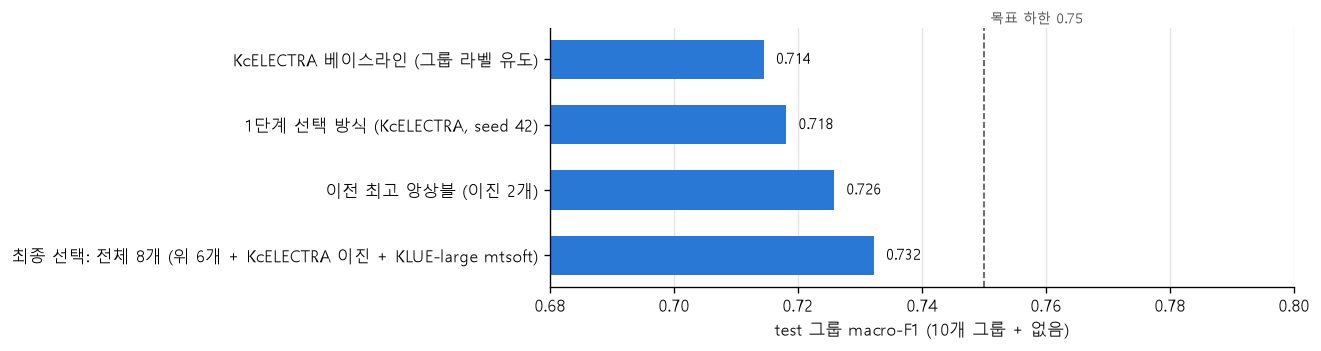

In [10]:
steps = pd.DataFrame([
    {"단계": "KcELECTRA 베이스라인 (그룹 라벨 유도)", "test 그룹 macro-F1": summarize("baseline_v2021_s42")["test 그룹"]},
    {"단계": "1단계 선택 방식 (KcELECTRA, seed 42)", "test 그룹 macro-F1": summarize(f"{CHOSEN}_s42")["test 그룹"]},
    {"단계": "이전 최고 앙상블 (이진 2개)", "test 그룹 macro-F1": ENS[prev]["test_group"]["macro_f1"]},
    {"단계": f"최종 선택: {FINAL}", "test 그룹 macro-F1": ENS[FINAL]["test_group"]["macro_f1"]},
])
show_fmt(steps, {"test 그룹 macro-F1": "{:.4f}"}, index=False)
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.barh(steps["단계"][::-1], steps["test 그룹 macro-F1"][::-1], color=SERIES[0], height=0.6)
for y, v in enumerate(steps["test 그룹 macro-F1"][::-1]):
    ax.text(v + 0.002, y, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(0.75, color="#52514e", ls="--", lw=1)
ax.text(0.751, len(steps) - 0.45, "목표 하한 0.75", fontsize=8.5, color="#52514e")
ax.set_xlim(0.68, 0.80)
ax.set_xlabel("test 그룹 macro-F1 (10개 그룹 + 없음)")
ax.grid(axis="x", color="#e4e4e0", lw=0.8)
save_fig(fig, FIG / "group_f1_progress.png")
plt.show()

## 6. 결론

| 단계 | test 그룹 macro-F1 | test 라벨 macro-F1 |
|---|---:|---:|
| KcELECTRA 단일 (베이스라인) | 0.714 | 0.567 |
| 1·2번: 그룹 동시 학습 + soft label (KcELECTRA) | 0.718 | 0.556 |
| 이전 최고 앙상블 (모델 2개) | 0.726 | 0.583 |
| **3번: 최종 앙상블 (모델 8개)** | **0.732** | **0.588** |

- **목표(그룹 macro-F1 0.75~0.8)에는 도달하지 못했다.** 세 방법을 모두 써서 베이스라인 대비 +0.018 올랐다.
- 그룹 동시 학습과 soft label은 그룹 성능을 거의 올리지 못했다. soft label은 행성 강도 표현에 쓸 수 있는 해석하기 쉬운 확률을 준다는 점에서 의미가 있다.
- 가장 확실한 수단은 **서로 다른 모델의 앙상블**이었지만, 8개 모델은 서비스 비용이 크다. 서비스에는 2~3개 앙상블 또는 단일 KLUE-large가 현실적이다.
- 남은 격차의 주된 원인은 라벨 자체의 불일치로 보인다. 평가자 1명이 나머지 4명의 합의를 맞히는 그룹 macro-F1이 0.51이다.

**다음으로 검토할 수 있는 것**
1. **평가 기준 재검토**: 서비스에 실제 쓰이는 ‘행성 기본색 일치(top-1/top-2)’처럼 서비스 목적에 맞는 지표를 주 지표로 합의
2. **증류**: 8개 앙상블의 soft 출력을 단일 모델에 학습시켜, 비용은 단일 모델 수준으로 유지하면서 앙상블 성능에 접근
3. **실제 일기 데이터 소량 수집·라벨링**: KOTE(댓글)와 일기 사이의 도메인 차이를 줄이는 것이 남은 개선 여지 중 가장 클 수 있음